## Simulering av krefter i fysikk - konstante og variable
 - I denne notatboken skal vi bygge videre på det grunnlaget vi begynte med i forrige notatbok (bevegelse med varierende akselerasjon). Her skal vi sørge for at denne akselerasjonen er bestemt av summen av kreftene på objektet. 
  - I første omgang skal vi se på situasjoner der summen av kreftene er konstant - slik at vi i følge Newtons første lov vil forvente konstant akselerasjon.
   - Videre skal vi se på situasjoner der kraftsummen ikke er konstant (...tenk etter... har vi allerede jobbet sett noen slike situasjoner i forsøk vi har gjennomført?)
   - Den grunnleggende metoden er den samme - vi deler opp situasjonen i diskrete tidssteg som vi itererer gjennom, og beregner ny posisjon/fart/akselerasjon/kraftsum for hvert tidssteg.


### Situasjon 1: Fall uten luftmotstand.

Et objekt med masse $m=4$ kg faller i vakuum. I dette tilfelle kjenner vi allerede akselerasjonen $a$, men i koden under vil vi likevel beregne denne ut fra Newtons andre lov, slik at vi enkelt kan bygge videre på koden senere, til å undersøke situasjoner der vi ikke kjenner $a$.

Fra Newtons første lov har vi at 
\begin{equation}
\Sigma F=m\cdot a.
\end{equation}

For å finne $a$, kan vi derfor finne 
\begin{equation}
a =\frac{\Sigma F}{m}.
\end{equation}

**Oppgave:**
Se på koden under, og fyll inn beregning av kraftsum,  beregning av a, og beregning av v og s inne i løkken.


In [ ]:
import numpy as np 
import matplotlib.pyplot as plt 

# Vi definerer størrelser vi kjenner
m = 4.0 #kg
g = 9.81 #kgm/s^2



#Vi definerer startverdier:
s = 0 #m
v = 0 #m/s
t = 0 #s

#FYLL INN UTTRYKK SOM LAR OSS BEREGNE KRAFTSUMMEN
sigma_F = ...

#FYLL INN UTTRYKK SOM LAR OSS BEREGNE AKSELERASJONEN
a = ...

#Vi velger hvor lenge vi skal kjøre simuleringen, og oppretter lister for å lagre beregninger:
t_slutt = 10
dt = 0.01
s_verdier = [s]  #Her vil alle posisjonsverdier lagres
v_verdier = [v]  #Her vil alle fartsverdier lagres
a_verdier = [a]  #Her vil alle akselerasjonsverdier lagres
t_verdier = [t]  #Her vil alle tidsverdier lagres

#Vi gjennomfører selve simuleringen - iterasjon gjennom tid!

while t < t_slutt:
    v = ... #FYLL INN: formel for fart gitt akselerasjon og dt
    s = ... #FYLL INN: formel for posisjon gitt fart og dt
    t = t + dt #går et tidssteg

    s_verdier.append(s)
    v_verdier.append(v)
    a_verdier.append(a)
    t_verdier.append(t)


plt.plot(t_verdier, s_verdier)
plt.title("Fall i vakuum, posisjon som funksjon av tid, m = " + str(m))
plt.xlabel('$t$ / s')
plt.ylabel('$s$ / m')
plt.show()

plt.plot(t_verdier, v_verdier)
plt.title("Fall i vakuum, fart som funksjon av tid, m = " + str(m))
plt.xlabel('$t$ / s')
plt.ylabel('$v$ / m/s')
plt.show()

**Oppgave:** Anta at objektet i situasjonen over slippes fra 10 meter høyde. Tilpass koden slik at den stopper når objektet treffer bakken. 

### Fall med luftmotstand:

Vi skal nå la samme objekt falle med luftmotstand. Vi har luftmotstand $L$ som en funksjon av fart $v$,
\begin{equation}
L=k\cdot v^{2},
\end{equation}

der $k$ er luftmotstandstallet.

Newtons andre lov gir oss nå
\begin{equation}
\Sigma F = G - L = m\cdot a.
\end{equation}

Fordi summen av kreftene avhenger av farten, vil akselerasjonen også avhenge av farten. Det betyr at den må beregnes på nytt for hvert tidssteg. Vi velger derfor å definere en funksjon $a(v)$ som beregner akselerasjon $a$ gitt fart $v$.

**Oppgave**: Fyll inn det som mangler i funksjonen $a(v)$ og løkken under:

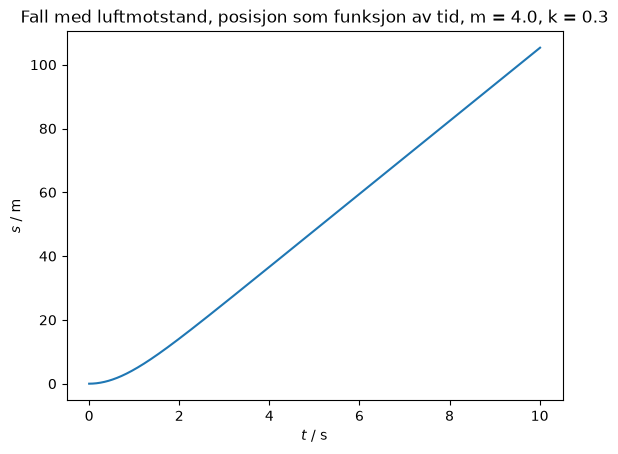

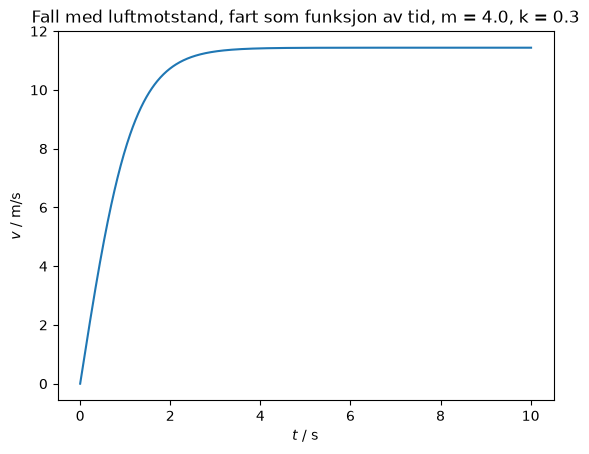

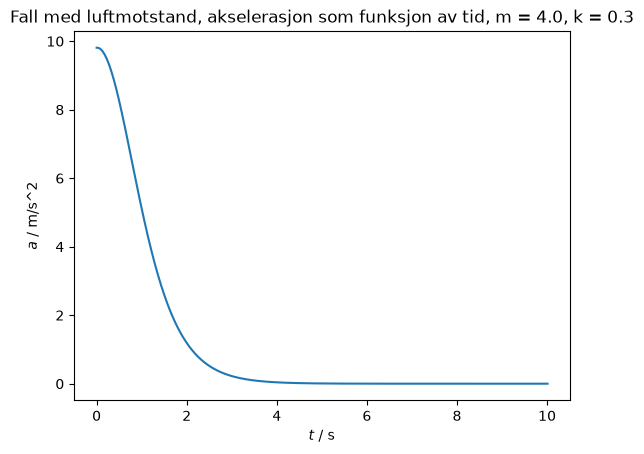

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt 

# Vi definerer størrelser vi kjenner
m = 4.0 #kg
g = 9.81 #kgm/s^2
k = 0.3 #Luftmostandstall, kg/m


#Vi definerer startverdier:
s = 0 #m
v = 0 #m/s
t = 0 #s

#FYLL INN DET SOM MANGLER I FUNKSJONEN:
def a(v):
    G = ...
    L = ...
    sigma_F = ...
    a = ...
    return a

#Vi velger hvor lenge vi skal kjøre simuleringen, og oppretter lister for å lagre beregninger:
t_slutt = 10
dt = 0.01
s_verdier = [s]  #Her vil alle posisjonsverdier lagres
v_verdier = [v]  #Her vil alle fartsverdier lagres
a_verdier = [a(v)]  #Her vil alle akselerasjonsverdier lagres
t_verdier = [t]  #Her vil alle tidsverdier lagres

#Vi gjennomfører selve simuleringen - iterasjon gjennom tid!

while t < t_slutt:

    a_verdier.append(a(v)) #Drøft - hvorfor lagres a før alt annet gjennomføres?

    v = ... #FYLL INN: formel for fart gitt akselerasjon og dt
    s = ... #FYLL INN: formel for posisjon gitt fart
    t = t + dt #går et tidssteg

    s_verdier.append(s)
    v_verdier.append(v)
    t_verdier.append(t)


plt.plot(t_verdier, s_verdier)
plt.title("Fall med luftmotstand, posisjon som funksjon av tid, m = " + str(m) + ", k = " + str(k))
plt.xlabel('$t$ / s')
plt.ylabel('$s$ / m')
plt.show()

plt.plot(t_verdier, v_verdier)
plt.title("Fall med luftmotstand, fart som funksjon av tid, m = " + str(m) + ", k = " + str(k))
plt.xlabel('$t$ / s')
plt.ylabel('$v$ / m/s')
plt.show()

plt.plot(t_verdier, a_verdier)
plt.title("Fall med luftmotstand, akselerasjon som funksjon av tid, m = " + str(m) + ", k = " + str(k))
plt.xlabel('$t$ / s')
plt.ylabel('$a$ / m/s^2')
plt.show()

**Oppgave:** Velg noen av målingene du gjennomførte i EØ4. Bruk beregnet $m$ og $k$. Sammenlign resultatene i den numeriske simuleringen med målingene dere fikk i virkeligheten.  